<img src="images/trump-reporters.jpg" width=700>

> *President Trump said in a social media post that he is offering a $1 million reward for anyone who reports voter fraud — in past elections or in the upcoming midterm elections — that leads to a conviction.*

# 01 - First look: NYS Voting

Researchers at Stanford and Columbia have prepared for us a snapshot of the New York State voter file. The state [makes it available to anyone who requests it](https://elections.ny.gov/freedom-information-law-foil-requests) via FOIL. 

The raw data includes all 62 New York counties, including New York City. The source file is a "snapshot" from December 27, 2022. As a table, it contains 20,919,063 rows, 114 columns and 19,937,571 distinct `state_vid` values. 

The term "snapshot" here means that on December 27th of 2022, a copy of the voter file was compiled. It records people at their then-current addresses with then-current information. If after that date they move or change parties or leave the state, their data will change. So the information for December 2023 might look different for a person than it did in 2022.

IDs are never null or blank. The same ID can occur under multiple registration statuses. (Why?) The file has 981,492 more rows than distinct IDs, so a row is not necessarily a distinct voter.

We have included a "skill" for our claude agent that adapts its behavior when you ask a question about some data. Every question goes through six steps: **Question → Plan → Compute → Check → Claim → Review**. You can tell the agent to ignore this if it's too heavy-handed. (Write "just", "quick", "only", "skip the steps", or simply ask for a plot or a table without asking a question.)

## The data

We have created a random sample of 100,000 voters from this file. That's not 100,000 rows, but voters. The distinction is that some voters have multiple lines. For the most part, they are `PURGE`/`ACTIVE` pairs, with someone moving from one part of the state to another (the old registration remaining on the roles purged, and the new registration is acitive at their new location).

Let's load the data!

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.fernet import Fernet
from getpass import getpass
from io import BytesIO
import gzip

# ask for the key
key = getpass("Enter the data key: ")

# first unencrypt the file
file = open("data/NY_2022_12_class_100k.csv.gz.enc", "rb")
data = Fernet(key.encode()).decrypt(file.read())

# then uncompress it and read it into a dataframe
voters = pd.read_csv(BytesIO(gzip.decompress(data)))

print(f"Loaded {len(voters):,} rows and {len(voters.columns)} columns.")

Loaded 104,942 rows and 106 columns.


In [3]:
# What are the dimensions of the table?
voters.shape

(104942, 106)

In [4]:
# Can we see the first few rows of the table?

voters.head()

,file_id,snapshot_id,snapshot_sub_id,state,reg_date,updated_date,last_contact_date,status,sex,race,...,voted_20191105,voted_20200428,voted_20200623,voted_20201103,voted_20210622,voted_20211102,voted_20220628,voted_20220823,voted_20221108,state_vid
0,NY-2343,40,NaN,NY,1997-06-10,NaN,NaN,ACTIVE,FEMALE,NOT REPORTED,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,NIHAIHNGCPHLKGENDCIDACPAJJHCDDMG
1,NY-2343,40,NaN,NY,1997-06-10,NaN,NaN,PURGED,FEMALE,NOT REPORTED,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,KJKMCJACPLCDGHPPPNBLBHOOLNLNIHPD
2,NY-2343,40,NaN,NY,1960-10-15,NaN,NaN,PURGED,FEMALE,NOT REPORTED,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CIFPKAMDDCLOOEPOOGJAKHLCHBFADDFG
3,NY-2343,40,NaN,NY,1997-06-11,NaN,NaN,ACTIVE,MALE,NOT REPORTED,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,LCLEIKIJIMDMFBCBALPEOGDNDPCJDIAE
4,NY-2343,40,NaN,NY,1997-06-12,NaN,NaN,ACTIVE,FEMALE,NOT REPORTED,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,FFCNPLEOMJFFIEDNKMGPEKNFEGFBINLA


In [5]:
# first set an option so you show all the columns of a data frame
pd.set_option("display.max_columns", None)

# then try again
voters.head()

,file_id,snapshot_id,snapshot_sub_id,state,reg_date,updated_date,last_contact_date,status,sex,race,party,birth_year,birth_date,age,voterfile_county,reg_address_zip,reg_address_city,mail_address_zip,mail_address_city,mail_address_state,unstandardized_party,unstandardized_sex,unstandardized_race,geocoded,geocoded_score,geocoded_type,geocoded_county,geocoded_puma_2000,geocoded_puma_2010,geocoded_puma_2020,county,voted_19921103,voted_19930914,voted_19931102,voted_19940913,voted_19941108,voted_19950912,voted_19951107,voted_19960307,voted_19960910,voted_19961105,voted_19970909,voted_19971104,voted_19980915,voted_19981103,voted_19990914,voted_19991102,voted_20000307,voted_20000912,voted_20001107,voted_20010911,voted_20011106,voted_20020910,voted_20021105,voted_20030909,voted_20031104,voted_20040302,voted_20040914,voted_20041102,voted_20050913,voted_20051108,voted_20060912,voted_20061107,voted_20070918,voted_20071106,voted_20080205,voted_20080909,voted_20081104,voted_20090908,voted_20091103,voted_20100914,voted_20101102,voted_20110913,voted_20111108,voted_20120424,voted_20120626,voted_20120913,voted_20121106,voted_20130910,voted_20131105,voted_20140624,voted_20140909,voted_20141104,voted_20150910,voted_20151103,voted_20160419,voted_20160628,voted_20160913,voted_20161108,voted_20170912,voted_20171107,voted_20180424,voted_20180626,voted_20180913,voted_20181106,voted_20190625,voted_20191105,voted_20200428,voted_20200623,voted_20201103,voted_20210622,voted_20211102,voted_20220628,voted_20220823,voted_20221108,state_vid
0,NY-2343,40,NaN,NY,1997-06-10,NaN,NaN,ACTIVE,FEMALE,NOT REPORTED,REP,1936,1936-11-20,86.0,SUFFOLK,11946,HAMPTON BAYS,NaN,SOUTHAMPTON,NY,REP,F,NaN,1,100.0,POINTADDRESS,SUFFOLK,4304.0,3305.0,3305.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,NIHAIHNGCPHLKGENDCIDACPAJJHCDDMG
1,NY-2343,40,NaN,NY,1997-06-10,NaN,NaN,PURGED,FEMALE,NOT REPORTED,DEM,1979,1979-03-16,43.0,SUFFOLK,11731,E NORTHPORT,NaN,HUNTINGTON,NY,DEM,F,NaN,1,99.9,STREETADDRESS,SUFFOLK,4301.0,3302.0,3302.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,KJKMCJACPLCDGHPPPNBLBHOOLNLNIHPD
2,NY-2343,40,NaN,NY,1960-10-15,NaN,NaN,PURGED,FEMALE,NOT REPORTED,REP,1916,1916-01-06,106.0,SUFFOLK,11725,COMMACK,NaN,HUNTINGTON,NY,REP,F,NaN,1,100.0,POINTADDRESS,SUFFOLK,4301.0,3302.0,3302.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CIFPKAMDDCLOOEPOOGJAKHLCHBFADDFG
3,NY-2343,40,NaN,NY,1997-06-11,NaN,NaN,ACTIVE,MALE,NOT REPORTED,OTHER,1965,1965-07-13,57.0,SUFFOLK,11778,ROCKY POINT,NaN,BROOKHAVEN,NY,OTH,M,NaN,1,100.0,STREETADDRESS,SUFFOLK,4303.0,3304.0,3304.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,LCLEIKIJIMDMFBCBALPEOGDNDPCJDIAE
4,NY-2343,40,NaN,NY,1997-06-12,NaN,NaN,ACTIVE,FEMALE,NOT REPORTED,NONPARTISAN,1950,1950-04-06,72.0,SUFFOLK,11768,NORTHPORT,NaN,HUNTINGTON,NY,BLK,F,NaN,1,100.0,POINTADDRESS,SUFFOLK,4301.0,3301.0,3301.0,SUFFOLK,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.

Now let's look at the `status` values. How many people are labled with each category? 

In [6]:
voters["status"].value_counts()

status
ACTIVE        61009
PURGED        38582
INACTIVE       4966
INELIGIBLE      385
Name: count, dtype: int64

Do the same thing, but with the variable describing if someone voted in the midterm election on November 8, 2022.

In [7]:
voters["voted_20221108"].value_counts()

voted_20221108
0.0    64389
1.0    23384
Name: count, dtype: int64

In [8]:
voters[["voted_20221108","status"]].value_counts()

voted_20221108  status  
0.0             ACTIVE      40136
1.0             ACTIVE      20873
0.0             PURGED      19304
                INACTIVE     4949
1.0             PURGED       2494
                INACTIVE       17
Name: count, dtype: int64

## Jumping far ahead

We can take that category counting idea and look at another variable. The `reg_date` is good, although maybe too granular. Let's strip off the month and day and look at just the years...

In [9]:
voters["reg_date"].str.split("-").str[0].head()

0    1997
1    1997
2    1960
3    1997
4    1997
Name: reg_date, dtype: object

We can now tally the categories. See that 2016 was a good year for registrations! This list is nice but what are we irresistably drawn to do next?

In [10]:
voters["reg_date"].str.split("-").str[0].value_counts()

reg_date
2016    5747
2020    5554
2008    5458
2004    4927
1992    4227
        ... 
1951       2
1954       2
1928       1
1922       1
1935       1
Name: count, Length: 78, dtype: int64

That's right, a graph! We can ask our claude agent to write the code for us, putting the cell just below this one. 

A bar chart of how many voters registered in each year, in order from the earliest year to the latest.

> *Below the cell that's highlighted, create a barplot (using Altair) of the counts of people registering each year, in numerical order by year.*

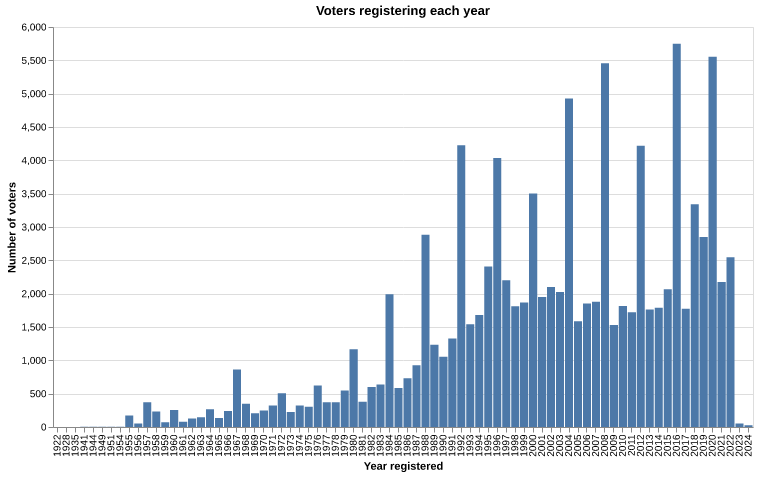

In [11]:
import altair as alt

alt.renderers.enable("png")  # draw as an image so it shows in VS Code

# take the year (the text before the first "-") and turn it into a number
reg_year = voters["reg_date"].str.split("-").str[0].astype(int)

# count voters per year, then put the years in numerical order
year_counts = reg_year.value_counts().sort_index()

# turn the counts into a small table that Altair can plot
year_table = year_counts.reset_index()
year_table.columns = ["year", "count"]

alt.Chart(year_table).mark_bar().encode(
    x=alt.X("year:O", title="Year registered", sort="ascending"),
    y=alt.Y("count:Q", title="Number of voters"),
).properties(title="Voters registering each year", width=700, height=400)

In [ ]:
import altair as alt

alt.renderers.enable("png")  # draw as an image so it shows in VS Code

registrations = (
    voters["reg_date"].str.split("-").str[0].astype(int)
    .value_counts().sort_index()
    .rename_axis("year").reset_index(name="count")
)

alt.Chart(registrations).mark_bar().encode(
    x=alt.X("year:O", title="Year", sort="ascending", axis=alt.Axis(values=list(range(1925, 2030, 5)), labelAngle=0)),
    y=alt.Y("count:Q", title="Number of registrations"),
).properties(title="Voter registrations by year", width=700, height=400)

What does this plot tell you? Can we break it down a little more?

> *Make the equivalent of a "pyramid plot" where we focus on just republican vs democratic registrations and we limit the data to 1996-2022.*

In [ ]:
import altair as alt

alt.renderers.enable("png")  # draw as an image so it shows in VS Code

voters["year"] = voters["reg_date"].str.split("-").str[0].astype(int)

pyramid = (
    voters[voters["party"].isin(["DEM", "REP"]) & voters["year"].between(1996, 2022)]
    .groupby(["year", "party"]).size().reset_index(name="count")
)
# Democrats are drawn to the left of zero, Republicans to the right
pyramid["signed_count"] = pyramid["count"].where(pyramid["party"] == "REP", -pyramid["count"])

alt.Chart(pyramid).mark_bar().encode(
    y=alt.Y("year:O", title="Year of registration", sort="ascending"),
    x=alt.X("signed_count:Q", title="Number of registrations", axis=alt.Axis(labelExpr="abs(datum.value)")),
    color=alt.Color("party:N", title="Party", scale=alt.Scale(domain=["DEM", "REP"], range=["#1f77b4", "#d62728"])),
).properties(title="Democratic vs Republican registrations by year, 1996-2022", width=600, height=500)

---
## Questions from the researchers

While this is a warm up data set, there's a great deal of information to be drawn about the previous midterm election. The researchers had these questions...

> There’s so much to do with the dataset. A few ideas that come to mind:
> 
> * Compare party registration across generations. Are older voters really more conservative than younger voters?
> 
> * Look at recent registrations. Are Dems or Reps gaining ground?
> 
> * Study who are the most politically active voters. Certainly older folks, but it might also vary with political geography. (Cool GIS task here). 
> 
> * How does party registration correlate with regional demographics, economics etc?

When we're done, we can ask our friend to write the chat as a markdown file and store it in our folder. That way we have a complete transcript of what we did.

> *Can you write a markdown version of this chat in the lesson_1 folder?*

---
## APIs

<img src="images/ts.png" width=700>

We are going to continue our work on APIs (Application Programming Interfaces) by looking at one of a number of services that provide access to social media posts. Here we are using [Social Fetch](https://www.socialfetch.dev/). See the course notes for a description of the service.

The file at `data/ts.json` (see your **Explorer** panel on the left) is the saved result of an API call to [Truth Social](http://truthsocial) for President Trump's account. We pulled the 20 most recent posts as of 2pm November 5th. Knowing what we know about dictioinaries and lists, tell me where you would find the sequence of posts. 

In [ ]:
# extend the powers of Python and now it acts like a browser in that it can request files from the web
import requests

# our key to make requests through Social Fetch
api_key = "sfk_EubwowBrxmebTcrUkZtlOarwYBqQRgvpbLxfYiVTKLFcfJjRZljAubcVCDcCFDlP"

# the special URL that specifies which social network and which profile to pull posts from
url = "https://api.socialfetch.dev/v1/truthsocial/profiles/realDonaldTrump/posts"

# away we go!
response = requests.get(
    url,
    headers={"x-api-key": api_key},
    params={"limit": 20},
)

# 200 means the request worked
print(response.status_code)

live_result = response.json()
print(live_result["data"]["lookupStatus"])
print(len(live_result["data"]["posts"]))

In [ ]:
import json
import pandas as pd

# first we open() the file
f = open("data/ts.json")

# then we load() the contents of the file into Python objects
api_result = json.load(f)

# The top level has "data" and "meta". The posts are inside "data".
print(api_result.keys())
print(api_result["data"].keys())
print(len(api_result["data"]["posts"]))

The list under `posts` has 20 entries, one dictionary per post. `pd.json_normalize` turns a list of dictionaries into a table, flattening nested pieces like `metrics` into columns such as `metrics.replies`. We also convert `createdAt` from text into a real date/time.

In [ ]:
# read the posts in as a pandas data frame
posts = pd.json_normalize(api_result["data"]["posts"])
print(type(posts))

# have a look
print(posts.shape)
posts.columns

# have a look... at the dimensions of the table and then the column names
print(posts.shape)
posts.columns

So 33 columns and 20 rows. Each row is a post. Below we look at just a few columns...

In [ ]:
# print out 20 posts but focus on the time, the text and some metrics

posts[["createdAt", "text", "metrics.replies", "metrics.reposts", "metrics.favorites"]]